# Point-cloud conditioning

A scan carries noise and far more points than a reconstruction needs. `filter_points` runs up to four steps in a fixed order, each seeing the points the one before kept:

1. **statistical outlier removal** (a point whose mean distance to its `k` nearest neighbours is more than `std_ratio` standard deviations above the cloud's mean goes),
2. **radius outlier removal** (fewer than `min_neighbors` other points within `radius`),
3. **voxel thinning** (one real point per cube, the one nearest the cube's mean),
4. **Poisson-disk thinning** (greedy, in index order: kept points are at least `min_distance` apart).

The CLI form is `meshioplusplus filter-points scan.ply clean.ply --outliers statistical --voxel 0.5`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp

rng = np.random.default_rng(3)


def noisy_sphere(n=6000, n_out=60, noise=0.01):
    v = rng.normal(size=(n, 3))
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    surf = v * (1.0 + rng.normal(0, noise, size=(n, 1)))
    stray = rng.uniform(-2.2, 2.2, size=(n_out, 3))
    stray = stray[np.linalg.norm(stray, axis=1) > 1.4]
    return np.vstack([surf, stray]), len(surf)


pts, n_surface = noisy_sphere()
scan = mp.Mesh(pts, [('vertex', np.arange(len(pts)).reshape(-1, 1))])
print(len(pts), 'points,', len(pts) - n_surface, 'of them stray')

6053 points, 53 of them stray


## Outliers

The statistical step compares each point's mean neighbour distance with the cloud's. The stray points are far from everything, so they go; a few tail points of the sphere may go with them at a tight ratio.

removed 53 | strays left: 0
radius step removed 53 | strays left: 0


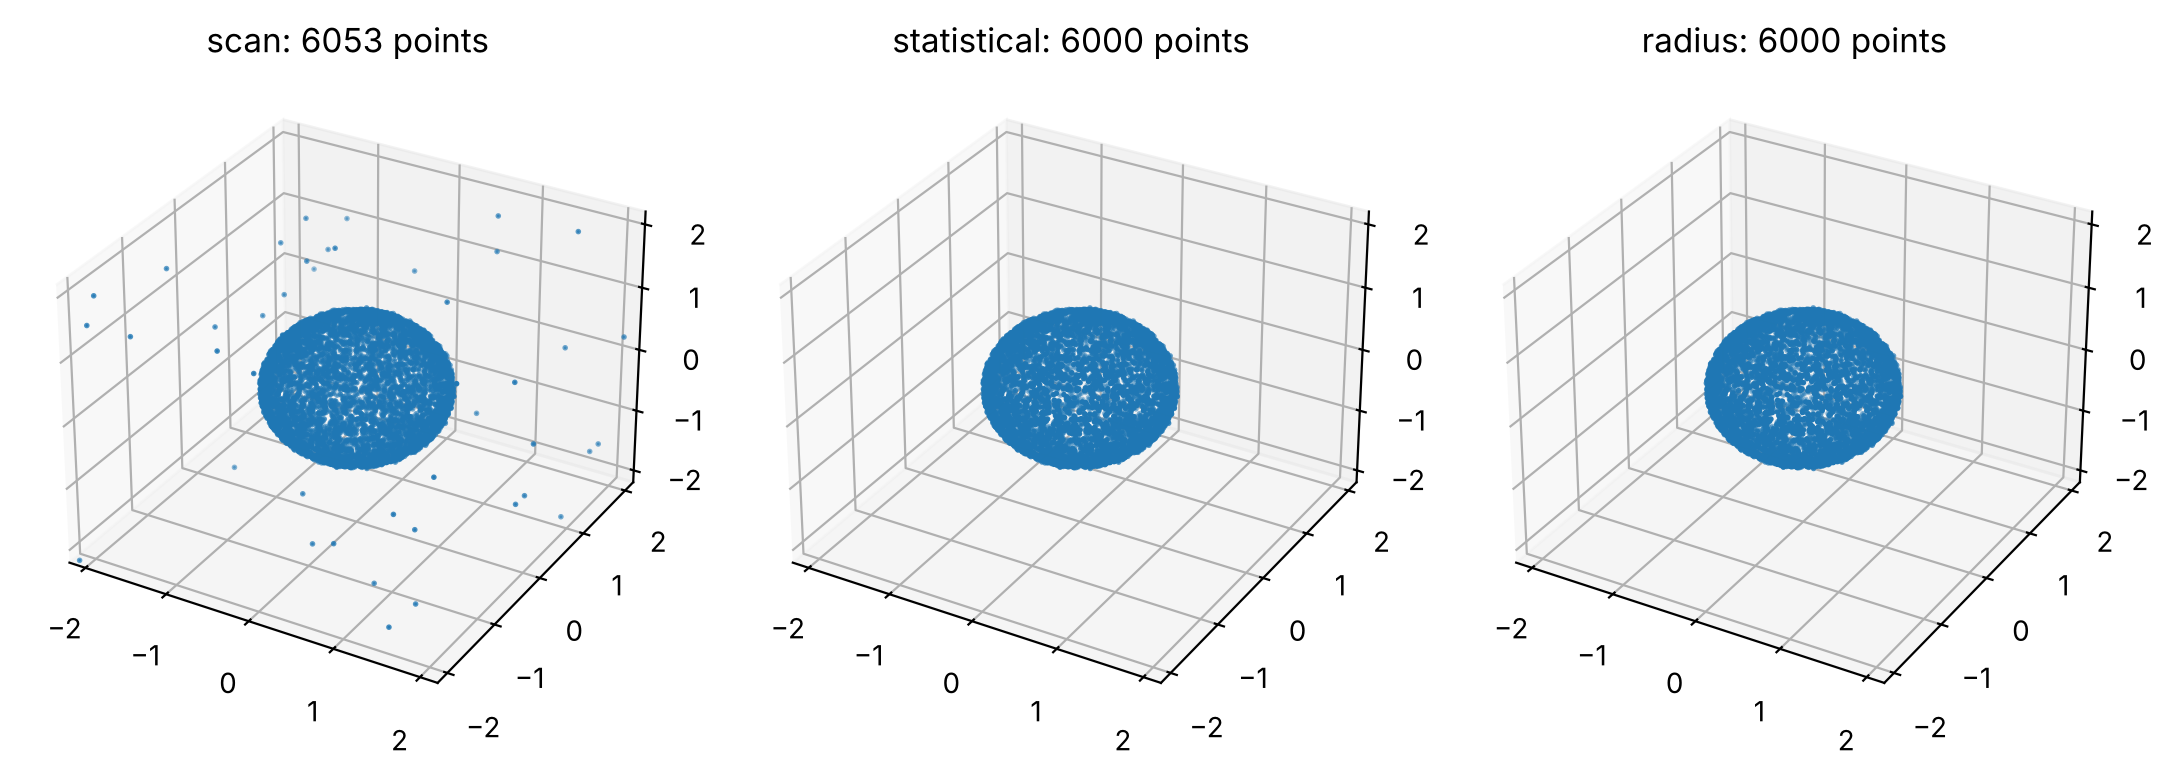

In [2]:
clean, rep = mp.filter_points(scan, statistical_k=16, std_ratio=2.0, return_report=True)
strays = rep['point_map'] >= n_surface
print('removed', rep['num_removed_statistical'], '| strays left:', int(strays.sum()))

by_radius, rr = mp.filter_points(scan, radius=0.12, min_neighbors=8, return_report=True)
print('radius step removed', rr['num_removed_radius'], '| strays left:', int((rr['point_map'] >= n_surface).sum()))

fig = plt.figure(figsize=(11, 4.2))
for k, (m, title) in enumerate([(scan, 'scan'), (clean, 'statistical'), (by_radius, 'radius')]):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    p = np.asarray(m.points)
    ax.scatter(*p.T, s=1)
    ax.set_title(f'{title}: {len(p)} points')
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_zlim(-2.2, 2.2)
plt.tight_layout(); plt.show()

## Thinning

Voxel thinning keeps one *real* point per cube (so every array survives untouched); Poisson-disk thinning gives a blue-noise-like sample whose kept points are at least `min_distance` apart.

clean 6000 -> voxel 1588 | poisson 703
closest pair of the Poisson-disk sample: 0.10002284564738732 (>= 0.1)


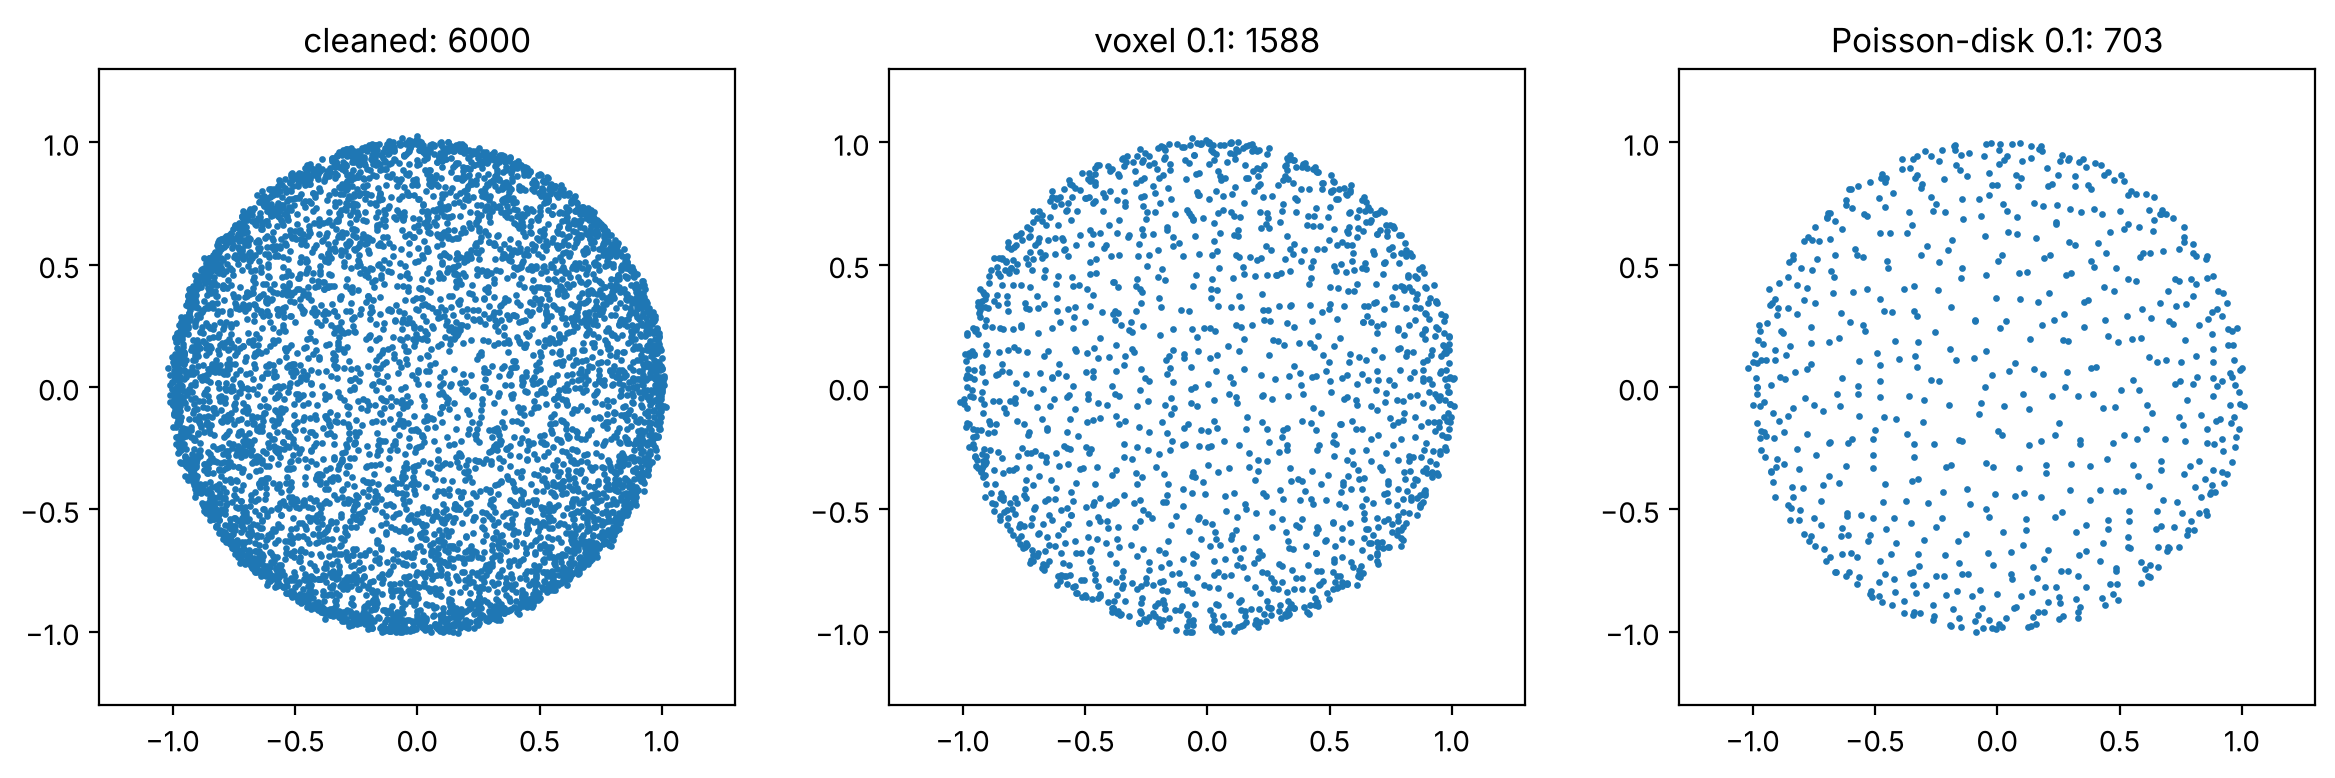

In [3]:
voxel, vr = mp.filter_points(clean, voxel_size=0.1, return_report=True)
poisson, pr = mp.filter_points(clean, min_distance=0.1, return_report=True)
print('clean', len(clean.points), '-> voxel', len(voxel.points), '| poisson', len(poisson.points))

p = np.asarray(poisson.points)
d = np.linalg.norm(p[:, None] - p[None], axis=-1)
np.fill_diagonal(d, np.inf)
print('closest pair of the Poisson-disk sample:', d.min(), '(>= 0.1)')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, m, t in zip(ax, (clean, voxel, poisson), ('cleaned', 'voxel 0.1', 'Poisson-disk 0.1')):
    q = np.asarray(m.points)
    a.scatter(q[:, 0], q[:, 1], s=2)
    a.set_title(f'{t}: {len(q)}'); a.set_aspect('equal'); a.set_xlim(-1.3, 1.3); a.set_ylim(-1.3, 1.3)
plt.tight_layout(); plt.show()

## Then reconstruct

The cleaned, thinned cloud is what `reconstruct_surface` wants: normals are estimated and a triangle surface is cut through the points.

In [4]:
surf = mp.reconstruct_surface(poisson, k=8)
print(type(surf).__name__, 'triangles:', sum(len(c.data) for c in surf.cells if c.type == 'triangle'))
stats = mp.compute_stats(surf)
print('area', round(stats['total_area'], 3), '(4*pi =', round(4 * np.pi, 3), ')')

Mesh triangles: 4540
area 12.73 (4*pi = 12.566 )
